# 💳 Kreditkarten-Kundensegmentierung mit K-Means
### K-Means Clustering | Unsupervised Machine Learning

**Projektfrage:** Können wir anhand der Kreditkartenaktivitäten sinnvolle Kundengruppen identifizieren?

**Projektziel:** Kunden mit ähnlichem Einkaufs-, Ausgaben- und Zahlungsverhalten in Gruppen einteilen.

**Problemtyp:** Clustering (Unsupervised Learning) – Es gibt keine Zielvariable (`y`), die vorhergesagt werden soll.

**Datensatz:** `CC GENERAL.csv` (8.950 Kunden, 18 Spalten)

**Datenquelle:** [Credit Card Dataset for Clustering auf Kaggle](https://www.kaggle.com/datasets/arjunbhasin2013/ccdata)

> In diesem Projekt gruppieren wir Kreditkartenkunden anhand ihres Ausgaben-, Bargeldabhebungs- und Zahlungsverhaltens. Anschließend analysieren und vergleichen wir die Eigenschaften der einzelnen Kundengruppen.

## 📖 Datenübersicht und Merkmalsbeschreibung (Data Dictionary)

Der Datensatz enthält **8.950 Kreditkartenkunden und 18 Spalten**. Jede Zeile beschreibt einen Kunden und sein Nutzungs- und Zahlungsverhalten.

Die folgende Tabelle zeigt alle Merkmale und ihre Bedeutung:

| Merkmal | Bedeutung | Erklärung |
|---|---|---|
| `CUST_ID` | Kunden-ID | Eindeutige Kennung eines Kunden |
| `BALANCE` | Kartensaldo | Höhe des erfassten Kreditkartensaldos |
| `BALANCE_FREQUENCY` | Saldohäufigkeit (0–1) | Wie regelmäßig der Kartensaldo erfasst wird |
| `PURCHASES` | Einkaufsbetrag | Gesamtsumme aller Einkäufe |
| `ONEOFF_PURCHASES` | Einmalkäufe | Gesamtsumme der Einkäufe ohne Ratenzahlung |
| `INSTALLMENTS_PURCHASES` | Ratenkäufe | Gesamtsumme der Einkäufe mit Ratenzahlung |
| `CASH_ADVANCE` | Bargeldvorschüsse | Gesamtsumme des abgehobenen Bargelds auf Kredit |
| `PURCHASES_FREQUENCY` | Einkaufshäufigkeit (0–1) | Wie regelmäßig der Kunde einkauft |
| `ONEOFF_PURCHASES_FREQUENCY` | Häufigkeit der Einmalkäufe (0–1) | Wie regelmäßig Einmalkäufe stattfinden |
| `PURCHASES_INSTALLMENTS_FREQUENCY` | Häufigkeit der Ratenkäufe (0–1) | Wie regelmäßig Einkäufe auf Raten erfolgen |
| `CASH_ADVANCE_FREQUENCY` | Bargeldvorschuss-Häufigkeit (0–1) | Wie regelmäßig Bargeldvorschüsse genutzt werden |
| `CASH_ADVANCE_TRX` | Bargeldtransaktionen | Anzahl der Bargeldvorschuss-Transaktionen |
| `PURCHASES_TRX` | Einkaufstransaktionen | Anzahl der durchgeführten Einkäufe |
| `CREDIT_LIMIT` | Kreditlimit | Maximal verfügbarer Kreditrahmen |
| `PAYMENTS` | Zahlungen | Gesamtsumme der geleisteten Zahlungen |
| `MINIMUM_PAYMENTS` | Mindestzahlungen | Höhe der geleisteten Mindestzahlungen |
| `PRC_FULL_PAYMENT` | Vollständige Zahlungen (0–1) | Anteil der vollständig beglichenen Salden |
| `TENURE` | Nutzungsdauer | Dauer der Kreditkartennutzung in Monaten |


## 1. Bibliotheken importieren

> Mit **Pandas** lesen und untersuchen wir die Daten. **NumPy** hilft bei Berechnungen. **Matplotlib** und **Seaborn** verwenden wir für die Diagramme

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

## 2. Datei laden

> Wir laden die Datei `CC GENERAL.csv` mit Pandas in unser Notebook und speichern die Daten als DataFrame `df`. Anschließend betrachten wir die ersten fünf Zeilen, um einen ersten Überblick über den Datensatz zu erhalten

In [2]:
df = pd.read_csv('CC GENERAL.csv')
df.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


## 3. Explorative Datenanalyse (EDA)

> Zuerst untersuchen wir die Struktur des Datensatzes. Wir prüfen die Anzahl der Zeilen und Spalten, die Datentypen und fehlende Werte.

In [3]:
df.shape

(8950, 18)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   str    
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHASES_TRX    

In [5]:
df.isnull().sum()

CUST_ID                               0
BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_INSTALLMENTS_FREQUENCY      0
CASH_ADVANCE_FREQUENCY                0
CASH_ADVANCE_TRX                      0
PURCHASES_TRX                         0
CREDIT_LIMIT                          1
PAYMENTS                              0
MINIMUM_PAYMENTS                    313
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64

In [6]:
# nur Spalten, die fehlende Werte enthalten
df.isnull().sum()[lambda s: s > 0]

CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64

In [7]:
df.describe().round(2)

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8949.00,8950.00,8637.00,8950.00,8950.00
mean,1564.47,0.88,1003.20,592.44,411.07,978.87,0.49,0.20,0.36,0.14,3.25,14.71,4494.45,1733.14,864.21,0.15,11.52
std,2081.53,0.24,2136.63,1659.89,904.34,2097.16,0.40,0.30,0.40,0.20,6.82,24.86,3638.82,2895.06,2372.45,0.29,1.34
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,50.00,0.00,0.02,0.00,6.00
25%,128.28,0.89,39.64,0.00,0.00,0.00,0.08,0.00,0.00,0.00,0.00,1.00,1600.00,383.28,169.12,0.00,12.00
50%,873.39,1.00,361.28,38.00,89.00,0.00,0.50,0.08,0.17,0.00,0.00,7.00,3000.00,856.90,312.34,0.00,12.00
75%,2054.14,1.00,1110.13,577.40,468.64,1113.82,0.92,0.30,0.75,0.22,4.00,17.00,6500.00,1901.13,825.49,0.14,12.00
max,19043.14,1.00,49039.57,40761.25,22500.00,47137.21,1.00,1.00,1.00,1.50,123.00,358.00,30000.00,50721.48,76406.21,1.00,12.00


In [8]:
print('Doppelte Kunden-IDs:', df['CUST_ID'].duplicated().sum())

Doppelte Kunden-IDs: 0


### 📊 Einkaufsverhalten untersuchen

> Wir untersuchen die Verteilung der Einkaufsbeträge und Kartensalden. Mit der logarithmischen Transformation `log1p` (`log(1 + x)`) werden große Werte besser dargestellt

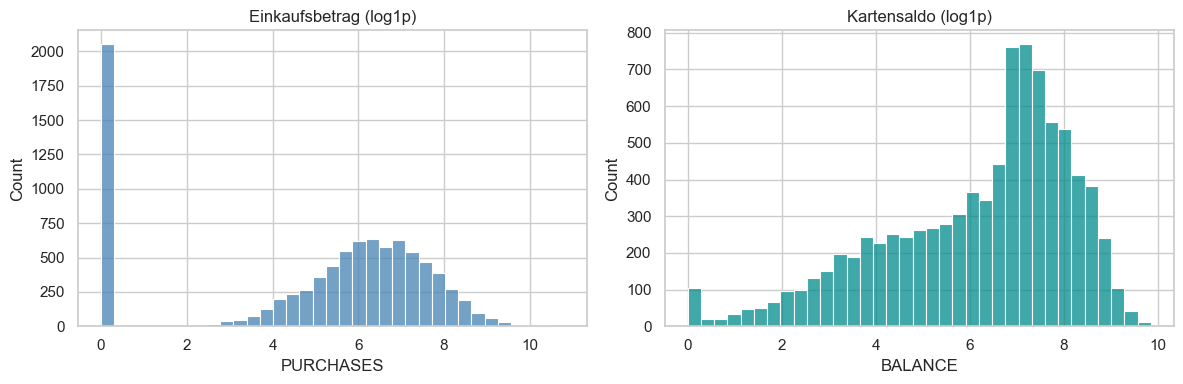

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(np.log1p(df['PURCHASES']), bins=35, color='steelblue', ax=axes[0])
sns.histplot(np.log1p(df['BALANCE']), bins=35, color='darkcyan', ax=axes[1])
axes[0].set_title('Einkaufsbetrag (log1p)')
axes[1].set_title('Kartensaldo (log1p)')
plt.tight_layout()
plt.show()

## 4. Datenbereinigung und Merkmalsauswahl

> `X` enthält die ausgewählten Merkmale für unser Modell. Für das Clustering wählen wir **sieben Merkmale** aus, die das Einkaufs-, Ausgaben- und Zahlungsverhalten der Kunden beschreiben. Die Kundenkennung `CUST_ID` wird nicht verwendet, da sie keine Informationen über das Kundenverhalten liefert.

**Ausgewählte Merkmale:**

`BALANCE`, `PURCHASES`, `CASH_ADVANCE`, `CREDIT_LIMIT`, `PAYMENTS`, `PURCHASES_FREQUENCY` und `PRC_FULL_PAYMENT`.

**Fehlende Werte:**

In `CREDIT_LIMIT` fehlt **1 Wert**, in `MINIMUM_PAYMENTS` fehlen **313 Werte**. Da wir `MINIMUM_PAYMENTS` nicht für das Modell verwenden, müssen wir diese Spalte nicht auffüllen.

Fehlende Werte in den ausgewählten Merkmalen ersetzen wir durch den jeweiligen **Median**

In [10]:
features = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT',
            'PAYMENTS', 'PURCHASES_FREQUENCY', 'PRC_FULL_PAYMENT']

X = df[features].copy()
X = X.fillna(X.median())
X.isnull().sum()

BALANCE                0
PURCHASES              0
CASH_ADVANCE           0
CREDIT_LIMIT           0
PAYMENTS               0
PURCHASES_FREQUENCY    0
PRC_FULL_PAYMENT       0
dtype: int64

### Merkmale skalieren (Scaling)

**Warum?** `CREDIT_LIMIT` kann mehrere Tausend betragen, während `PURCHASES_FREQUENCY` zwischen 0 und 1 liegt. K-Means vergleicht Abstände. Ohne Anpassung könnten große Zahlenwerte das Ergebnis zu stark beeinflussen.

- **`log1p`** reduziert den Einfluss sehr hoher Geldbeträge.
- **`StandardScaler`** bringt die Merkmale auf vergleichbare Skalen.

In [11]:
from sklearn.preprocessing import StandardScaler

amounts = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS']

X[amounts] = np.log1p(X[amounts])
X_scaled = StandardScaler().fit_transform(X)

## 5. K-Means und die Anzahl der Cluster

> K-Means fasst Kunden mit ähnlichem Verhalten zusammen. Wir legen die Anzahl der Gruppen nicht sofort fest, sondern vergleichen **2 bis 7 Cluster**.

**Elbow-Methode:** Mit mehr Clustern sinkt die *Inertia*. Wir suchen einen Bereich, ab dem diese Verbesserung deutlich kleiner wird.

**Silhouette Score:** Er zeigt, wie gut sich die Gruppen voneinander unterscheiden (ungefähr **−1 bis +1**; ein höherer Wert ist meist besser).

Für die Berechnung des Silhouette Scores verwenden wir eine feste **Stichprobe von 1.200 Kunden**, damit der Vergleich schneller läuft. Das K-Means-Modell wird trotzdem auf dem gesamten Datensatz trainiert

In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

scores, inertia = [], []
for k in range(2, 8):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    scores.append(silhouette_score(X_scaled, labels, sample_size=1200, random_state=42))
    inertia.append(model.inertia_)

results = pd.DataFrame({'K': range(2, 8), 'Silhouette': scores, 'Inertia': inertia})
results.round(3)

,K,Silhouette,Inertia
0,2,0.276,45870.261
1,3,0.272,36990.813
2,4,0.291,30366.639
3,5,0.292,26785.427
4,6,0.285,23934.327
5,7,0.287,21592.875


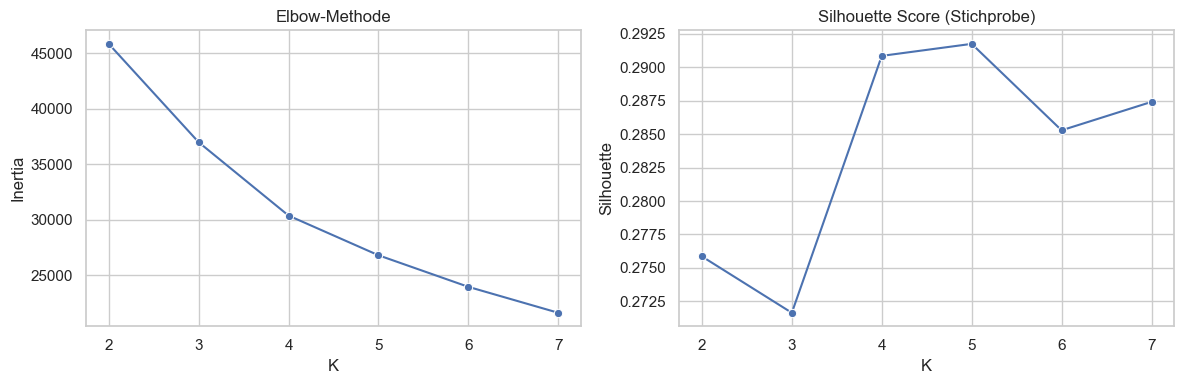

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=results, x='K', y='Inertia', marker='o', ax=axes[0])
sns.lineplot(data=results, x='K', y='Silhouette', marker='o', ax=axes[1])
axes[0].set_title('Elbow-Methode')
axes[1].set_title('Silhouette Score (Stichprobe)')
plt.tight_layout()
plt.show()

## 6. Finales K-Means-Modell

> Wir wählen die Clusterzahl mit dem höchsten Silhouette Score der Stichprobe. Das ist ein **Orientierungswert**, kein Beweis für die einzig richtige Anzahl. Wir prüfen anschließend auch, ob die Gruppen groß genug und sinnvoll interpretierbar sind.

`random_state=42` hilft, die Ergebnisse zu reproduzieren. `n_init=10` testet mehrere Startpositionen für die Clusterzentren

In [14]:
best_k = int(results.loc[results['Silhouette'].idxmax(), 'K'])
model = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df['Cluster'] = model.fit_predict(X_scaled)

print('Gewähltes K:', best_k)
print('Kundenzahl je Cluster:')
print(df['Cluster'].value_counts().sort_index())

Gewähltes K: 5
Kundenzahl je Cluster:
Cluster
0    1732
1    1330
2    1297
3    2394
4    2197
Name: count, dtype: int64


## 7. Kundensegmente analysieren

> Mit `groupby()` vergleichen wir die Kundengruppen. Wir verwenden den **Median** für Einkäufe, Salden und Zahlungen, weil dieser weniger empfindlich auf sehr hohe Einzelwerte reagiert als der Durchschnitt

In [15]:
profile = df.groupby('Cluster')[features].median().round(2)
profile

,BALANCE,PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,PURCHASES_FREQUENCY,PRC_FULL_PAYMENT
Cluster,,,,,,,
0,2336.44,766.58,1545.23,5000.0,1619.38,0.67,0.00
1,23.96,162.60,0.00,2000.0,178.15,0.33,0.00
2,80.51,872.70,0.00,4000.0,1043.56,0.92,0.83
3,975.44,895.52,0.00,3500.0,1018.37,0.79,0.00
4,1493.44,0.00,1192.79,3000.0,764.94,0.00,0.00


In [16]:
counts = df['Cluster'].value_counts().sort_index()
shares = (counts / len(df) * 100).round(1)
pd.DataFrame({'Kunden': counts, 'Anteil (%)': shares})

,Kunden,Anteil (%)
Cluster,,
0,1732,19.4
1,1330,14.9
2,1297,14.5
3,2394,26.7
4,2197,24.5


### Heatmap – Unterschiede zwischen den Kundengruppen

Die Heatmap zeigt die **Durchschnittswerte der skalierten Merkmale** je Cluster. **0** entspricht dem Gesamtdurchschnitt. Positive Werte liegen darüber, negative darunter

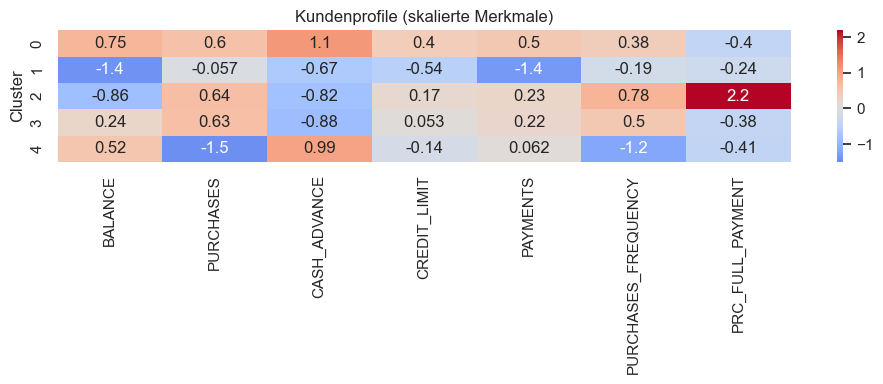

In [17]:
scaled_profile = pd.DataFrame(X_scaled, columns=features)
scaled_profile['Cluster'] = df['Cluster']
plt.figure(figsize=(10, 4))
sns.heatmap(scaled_profile.groupby('Cluster').mean(), annot=True, cmap='coolwarm', center=0)
plt.title('Kundenprofile (skalierte Merkmale)')
plt.tight_layout()
plt.show()

## 8. Cluster grafisch darstellen

> Jede Farbe steht für eine Kundengruppe. Für das Diagramm verwenden wir nur zwei der sieben Merkmale: Einkaufsbeträge und Bargeldvorschüsse. Beide Werte werden mit `log1p` transformiert

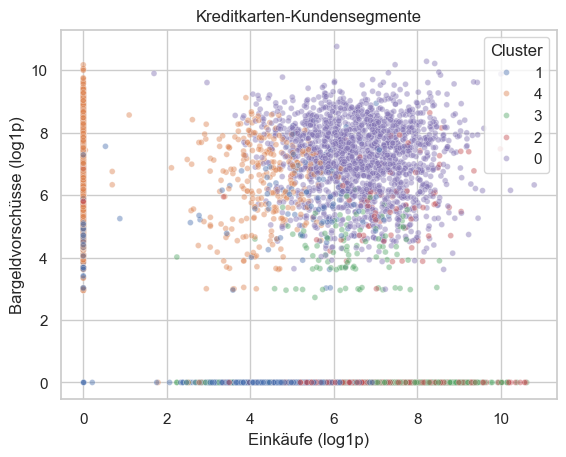

In [18]:
plot_df = pd.DataFrame({
    'Einkäufe (log1p)': np.log1p(df['PURCHASES']),
    'Bargeldvorschüsse (log1p)': np.log1p(df['CASH_ADVANCE']),
    'Cluster': df['Cluster'].astype(str)
})
sns.scatterplot(data=plot_df, x='Einkäufe (log1p)', y='Bargeldvorschüsse (log1p)',
                hue='Cluster', alpha=0.45, s=18)
plt.title('Kreditkarten-Kundensegmente')
plt.show()

### Bonus: PCA – Sieben Merkmale in zwei Dimensionen

Wir nutzen **PCA ausschließlich zur Visualisierung**. Das K-Means-Modell wird nicht erneut mit PCA trainiert. Die Darstellung in zwei Dimensionen kann nicht alle Unterschiede zwischen den Kunden vollständig abbilden.

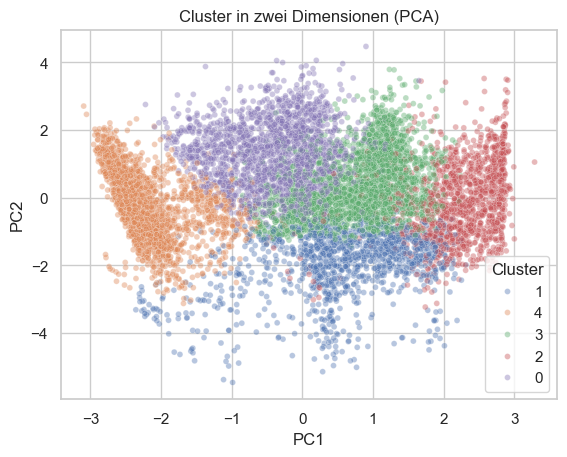

In [19]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
points = pca.fit_transform(X_scaled)
sns.scatterplot(x=points[:, 0], y=points[:, 1], hue=df['Cluster'].astype(str),
                alpha=0.4, s=18)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Cluster in zwei Dimensionen (PCA)')
plt.show()

## 9. Ergebnisse als CSV speichern

> Wir speichern die Zuordnung der Kunden zu ihren Clustern in einer neuen Datei `credit_card_segments.csv`. Die Datei wird im **aktuellen Arbeitsverzeichnis** gespeichert – normalerweise im selben Ordner wie das Notebook.

In [20]:
df[['CUST_ID', 'Cluster']].to_csv('credit_card_segments.csv', index=False)
print('Gespeichert: credit_card_segments.csv')

Gespeichert: credit_card_segments.csv


## 10. Ergebnisse und Fazit

### Ergebnisse der Kundensegmentierung

Mit dem K-Means-Modell haben wir die **8.950 Kreditkartenkunden in fünf Gruppen** eingeteilt. Die Gruppen unterscheiden sich in ihrem Einkaufs-, Ausgaben- und Zahlungsverhalten.

Die folgende Tabelle zeigt die Ergebnisse unseres Modells:

| Cluster | Kunden | Anteil | Kundenverhalten |
|---|---:|---:|---|
| **0** | 1.732 | 19,4 % | Hohe Kartensalden und Bargeldvorschüsse, mittlere Einkaufsbeträge |
| **1** | 1.330 | 14,9 % | Niedrige Kartensalden und geringe Einkaufsaktivität |
| **2** | 1.297 | 14,5 % | Häufige Einkäufe und oft vollständige Zahlungen |
| **3** | 2.394 | 26,7 % | Regelmäßige Einkäufe, mittlere Kartensalden und wenig Bargeldvorschüsse |
| **4** | 2.197 | 24,5 % | Hohe Bargeldvorschüsse und sehr geringe Einkaufsaktivität |

> Die Beschreibung basiert auf den Medianwerten der Cluster. Die Clusternummern sind keine Rangfolge und haben keine feste fachliche Bedeutung.

### Bewertung des Modells

Für die Segmentierung wurde **K = 5** gewählt. Der Silhouette Score liegt bei ungefähr **0,292**.

Das Ergebnis zeigt, dass sich unterschiedliche Kundengruppen erkennen lassen. Die Trennung zwischen den Gruppen ist jedoch nicht besonders stark.

Da vier Cluster einen sehr ähnlichen Silhouette Score erzielen, ist die Wahl von fünf Clustern nicht eindeutig optimal. Auch die Verständlichkeit der Kundengruppen ist bei der Bewertung wichtig.

### Fazit

In diesem Projekt haben wir Kreditkartendaten analysiert und mit **K-Means Clustering** Kunden mit ähnlichem Verhalten gruppiert.

Die Ergebnisse zeigen Unterschiede bei Einkäufen, Bargeldvorschüssen, Kreditkartensalden und Zahlungen.

Diese Kundensegmente können Unternehmen helfen, das Kundenverhalten besser zu verstehen und gezielte Service- oder Marketingstrategien zu untersuchen.

**Grenzen des Modells:** Die Ergebnisse basieren auf einem öffentlichen Beispieldatensatz und sieben ausgewählten Merkmalen. Für eine praktische Anwendung müssten die Cluster weiter überprüft werden. Sie reichen nicht aus, um die Kreditwürdigkeit einzelner Kunden zuverlässig zu bewerten.

**Zusammenfassung:** K-Means bietet eine einfache Möglichkeit, Kundengruppen zu erkennen und ihr Verhalten besser zu verstehen.

**Quellen:** [Datensatz](https://www.kaggle.com/datasets/arjunbhasin2013/ccdata) · [Projektinspiration](https://amanxai.com/2022/10/03/credit-card-clustering-with-machine-learning/) · [KMeans-Dokumentation (scikit-learn)](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)